In [ ]:
import os, subprocess, time, shutil
os.makedirs('/content/a5',exist_ok=True); shutil.unpack_archive('/content/a5.zip','/content/a5'); os.chdir('/content/a5')
print(subprocess.run(['nvidia-smi','--query-gpu=name,memory.total','--format=csv'],capture_output=True,text=True).stdout)
_T={'t':time.time()}
def _pre(info=None): _T['t']=time.time()
def _post(res=None): print(f"[tiempo celda] {time.time()-_T['t']:.2f} s")
ip=get_ipython(); ip.events.register('pre_run_cell',_pre); ip.events.register('post_run_cell',_post)


name, memory.total [MiB]
Tesla T4, 15360 MiB

[tiempo celda] 0.00 s


# Práctica de Deep Learning para Finanzas · Avance 5 (capítulo 11)
**Ciencia de Datos Aplicada a la Economía** · Prof. Rubén Miguel Rodríguez Rangel · Enrique · [PLACEHOLDER: compañero de equipo]

Tema: indicadores técnicos como variables de entrada. ¿Aportan información o solo complejidad?

Entregable (protocolo §5): comparación con y sin indicadores, resultados de TE y pronóstico futuro. **TE se evalúa una sola vez**
(celda 9), después de elegir la versión final con VA; antes de esa celda ninguna cuenta usa sus filas.

**Cómo correrlo:** en Colab o en cualquier Python 3. *Ejecutar todas*; la celda 2 pide subir `avance5_insumos.zip`.

## 1. Configuración y versiones

In [ ]:
import json, os, platform, shutil, sys
import numpy as np, pandas as pd, matplotlib, sklearn
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

SEMILLA = 42
VENTANA = 20                    # 20 rezagos (Avance 1) y 20 cierres / 20 rendimientos para los indicadores
UMBRALES = [0.0005, 0.001, 0.002, 0.003, 0.005]   # los mismos δ del Avance 3
CAPITAL, COSTO = 100_000, 0.001                    # protocolo §9
LAGS = [f"r_lag{i}" for i in range(VENTANA)]
IND = ["dist_sma20", "vol20"]
EN_COLAB = "google.colab" in sys.modules
for d in ["data/processed", "outputs", "figures"]:
    os.makedirs(d, exist_ok=True)
VERSIONES = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
             "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__}
print(VERSIONES, "| semilla", SEMILLA)

{'python': '3.13.16', 'numpy': '2.4.6', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'matplotlib': '3.10.0'} | semilla 42
[tiempo celda] 0.93 s


## 2. Insumos de los Avances 1 y 2

In [ ]:
INSUMOS = ["data/processed/ventanas_btcusdt_1d.csv", "data/processed/btcusdt_1d_auditado.csv", "outputs/particiones_avance1.csv",
           "outputs/seleccion_avance2.json", "outputs/experimentos_avance2.csv"]
if EN_COLAB and not all(map(os.path.exists, INSUMOS)):
    from google.colab import files
    print("Sube avance5_insumos.zip")
    shutil.unpack_archive(next(iter(files.upload())), ".")
faltan = [f for f in INSUMOS if not os.path.exists(f)]
if faltan:
    raise FileNotFoundError(f"Faltan insumos: {faltan}. Detengo el flujo.")
SELECCION = json.load(open(INSUMOS[3]))
print("Modelo elegido con VA en el Avance 2:", SELECCION["elegido"], f"(corrida: {SELECCION['modo']})")

Modelo elegido con VA en el Avance 2: Regresión lineal (20 rezagos) (corrida: t4)
[tiempo celda] 0.00 s


## 3. Indicadores: definición y cálculo solo con historia hasta *t*
| Indicador | Qué representa | Ventana | Fórmula (al cierre de *t*) |
|---|---|---|---|
| `dist_sma20` | Separación del precio respecto de su tendencia reciente | 20 cierres (*t*−19 … *t*) | cierre<sub>t</sub> / SMA20<sub>t</sub> − 1, con SMA20<sub>t</sub> = promedio de los 20 cierres |
| `vol20` | Variabilidad reciente del activo | 20 rendimientos diarios (*t*−19 … *t*) | desviación estándar **muestral** (ddof = 1) de esos rendimientos, **sin anualizar** |

Las ventanas son fijas (las recomendadas por el protocolo); no se eligió ningún parámetro, así que nada se ajustó con VA ni TE.
Se calculan con ventanas móviles hacia atrás (`rolling`, `min_periods` = ventana): los primeros valores quedan vacíos y
**no se rellenan hacia atrás**. Las dos son razones, sin unidades de precio (estacionarias, como se anticipó en el Avance 3).

In [ ]:
precios = pd.read_csv(INSUMOS[1], parse_dates=["fecha"]).set_index("fecha").sort_index()
assert precios.index.is_unique and (precios.close > 0).all()

def indicadores(p):
    sma = p.close.rolling(VENTANA, min_periods=VENTANA).mean()
    r = p.close.pct_change()
    return pd.DataFrame({"dist_sma20": p.close / sma - 1, "vol20": r.rolling(VENTANA, min_periods=VENTANA).std(ddof=1)})

ind = indicadores(precios)
# 1) sin relleno hacia atrás: vacíos exactamente al inicio
assert ind.dist_sma20.isna().sum() == VENTANA - 1 and ind.vol20.isna().sum() == VENTANA, "relleno o huecos inesperados"
# 2) sin datos futuros: recalcular cortando la historia en 5 fechas da el mismo valor en esa fecha
for t in precios.index[[25, 500, 1500, 2600, -1]]:
    assert np.allclose(indicadores(precios.loc[:t]).loc[t], ind.loc[t]), f"el indicador de {t.date()} usa datos posteriores"
tabla_ind = pd.DataFrame([
    {"indicador": "dist_sma20", "representa": "separación del cierre respecto de su SMA de 20 cierres", "ventana": "20 cierres",
     "formula": "cierre_t / mean(cierre_t-19..t) - 1", "primera_fecha_valida": ind.dist_sma20.first_valid_index().date()},
    {"indicador": "vol20", "representa": "volatilidad de los últimos 20 rendimientos diarios", "ventana": "20 rendimientos",
     "formula": "std muestral(r_t-19..t), sin anualizar", "primera_fecha_valida": ind.vol20.first_valid_index().date()}])
tabla_ind.to_csv("outputs/indicadores.csv", index=False)
print(f"Primer precio: {precios.index.min().date()}. Sin dato válido: {VENTANA - 1} días (SMA20) y {VENTANA} días (vol20); no se rellenan.")
tabla_ind

Primer precio: 2018-08-23. Sin dato válido: 19 días (SMA20) y 20 días (vol20); no se rellenan.


,indicador,representa,ventana,formula,primera_fecha_valida
0,dist_sma20,separación del cierre respecto de su SMA de 20...,20 cierres,cierre_t / mean(cierre_t-19..t) - 1,2018-09-11
1,vol20,volatilidad de los últimos 20 rendimientos dia...,20 rendimientos,"std muestral(r_t-19..t), sin anualizar",2018-09-12


[tiempo celda] 0.04 s


## 4. Particiones del Avance 1 y mismo periodo evaluable
Se unen los indicadores de la **fecha de emisión** (cierre de *t*) a cada ejemplo. Si alguna fila no tuviera indicador válido se
retiraría de **las dos** versiones, para comparar en las mismas fechas. Las filas de TE se apartan y no se tocan hasta la celda 9.

In [ ]:
datos = pd.read_csv(INSUMOS[0], parse_dates=["fecha_emision", "fecha_objetivo"])
ref = pd.read_csv(INSUMOS[2]).set_index("conjunto")
for k in ["TR", "VA", "TE"]:
    p = datos[datos.conjunto == k]
    assert len(p) == ref.loc[k, "ejemplos"], f"{k}: {len(p)} ejemplos ≠ Avance 1"
    assert str(p.fecha_objetivo.min().date()) == ref.loc[k, "primera_fecha_objetivo"], f"{k}: fechas ≠ Avance 1"
datos = datos.merge(ind, left_on="fecha_emision", right_index=True, how="left", validate="1:1")
validas = datos[IND].notna().all(axis=1)
print(f"Filas sin indicador válido (retiradas de ambas versiones): {(~validas).sum()}")
datos = datos[validas].sort_values("fecha_objetivo").reset_index(drop=True)
# vol20 en t es la desviación de los mismos 20 rendimientos que ya están en la fila (r_lag0 … r_lag19)
assert np.allclose(datos.vol20, datos[LAGS].std(axis=1, ddof=1)), "vol20 no coincide con los 20 rendimientos de la fila"
INICIO_TE = pd.Timestamp(ref.loc["TE", "primera_fecha_objetivo"])
TR, VA = datos[datos.conjunto == "TR"].reset_index(drop=True), datos[datos.conjunto == "VA"].reset_index(drop=True)
_TE = datos[datos.conjunto == "TE"].reset_index(drop=True)     # sellado: solo lo usa evaluar_te_una_vez()
assert VA.fecha_objetivo.max() < INICIO_TE
print(f"TR {len(TR)} | VA {len(VA)} | TE apartado ({len(_TE)} filas desde {INICIO_TE.date()})")

Filas sin indicador válido (retiradas de ambas versiones): 0
TR 2067 | VA 442 | TE apartado (444 filas desde 2025-08-18)
[tiempo celda] 0.05 s


## 5. Modelo del Avance 2: versión A (rezagos) y versión B (rezagos + 2 indicadores)
Es el modelo que el Avance 2 eligió con VA. Las dos versiones usan el mismo procedimiento, las mismas fechas y la misma semilla;
solo cambian las columnas de entrada. Los escaladores se ajustan **solo con TR**. Si el elegido fue una red, se reentrena con
su configuración y las épocas de su mejor época, sin parada temprana (igual que el Avance 3); en la LSTM los 20 rendimientos
van como secuencia y los indicadores entran junto al último estado oculto.

In [ ]:
ELEGIDO = SELECCION["elegido"]
RED = "MLP" if ELEGIDO.startswith("MLP") else "LSTM" if ELEGIDO.startswith("LSTM") else None
if RED:
    import torch
    from torch import nn
    exp2 = pd.read_csv(INSUMOS[4])
    cfg = exp2[(exp2.red == RED) & (exp2.semilla == SEMILLA) & (ELEGIDO.split("(")[1].split()[0] == exp2.neuronas.astype(str))].iloc[0]
    NEURONAS, EPOCAS, LR, LOTE = int(cfg.neuronas), int(cfg.mejor_epoca), float(cfg.lr), int(cfg.lote)
    print(f"{RED} con {NEURONAS} neuronas, {EPOCAS} épocas, lr {LR}, lote {LOTE}")
elif not ELEGIDO.startswith("Regresión lineal"):
    raise ValueError(f"Modelo no reconocido: {ELEGIDO}")

def ajustar(Xtr, ytr):
    """X escalada (20 rezagos y, si hay, indicadores al final); devuelve una función que predice y escalada."""
    if RED is None:
        m = LinearRegression().fit(Xtr, ytr)
        return lambda X: m.predict(X).ravel()
    torch.manual_seed(SEMILLA)
    extra = Xtr.shape[1] - VENTANA
    if RED == "MLP":
        modelo = nn.Sequential(nn.Linear(Xtr.shape[1], NEURONAS), nn.ReLU(), nn.Linear(NEURONAS, NEURONAS), nn.ReLU(), nn.Linear(NEURONAS, 1))
        forma = lambda X: torch.tensor(X, dtype=torch.float32)
    else:
        class LSTM(nn.Module):
            def __init__(self):
                super().__init__()
                self.lstm, self.salida = nn.LSTM(1, NEURONAS, batch_first=True), nn.Linear(NEURONAS + extra, 1)
            def forward(self, x):
                sec, otras = x[:, :VENTANA].flip(1).unsqueeze(-1), x[:, VENTANA:]   # de r_lag19 (viejo) a r_lag0
                return self.salida(torch.cat([self.lstm(sec)[0][:, -1], otras], 1))
        modelo = LSTM()
        forma = lambda X: torch.tensor(X, dtype=torch.float32)
    xt, yt = forma(Xtr), torch.tensor(ytr, dtype=torch.float32).reshape(-1, 1)
    opt, mse, azar = torch.optim.Adam(modelo.parameters(), lr=LR), nn.MSELoss(), torch.Generator().manual_seed(SEMILLA)
    for _ in range(EPOCAS):
        for idx in torch.randperm(len(xt), generator=azar).split(LOTE):
            opt.zero_grad(); mse(modelo(xt[idx]), yt[idx]).backward(); opt.step()
    modelo.eval()
    def predecir(X):
        with torch.no_grad():
            return modelo(forma(X)).numpy().ravel()
    return predecir

def metricas(real, est):
    return {"MAE": mean_absolute_error(real, est), "RMSE": mean_squared_error(real, est) ** 0.5}

def entrenar(cols):
    escX, escY = StandardScaler().fit(TR[cols]), StandardScaler().fit(TR[["y"]])
    assert escX.n_samples_seen_ == len(TR) == escY.n_samples_seen_, "escaladores ajustados fuera de TR"
    predecir = ajustar(escX.transform(TR[cols]), escY.transform(TR[["y"]]).ravel())
    return lambda p: escY.inverse_transform(predecir(escX.transform(p[cols])).reshape(-1, 1)).ravel()

VERSIONES_MODELO = {"A: rezagos": LAGS, "B: rezagos + indicadores": LAGS + IND}
modelos = {v: entrenar(c) for v, c in VERSIONES_MODELO.items()}
pred_va = {v: f(VA) for v, f in modelos.items()}
filas = [{"version": v, "variables": len(VERSIONES_MODELO[v]), **metricas(VA.y.to_numpy(), p),
          "desv_pred": float(np.std(p)), "desv_pred / desv_y": float(np.std(p) / VA.y.std(ddof=0))} for v, p in pred_va.items()]
filas.append({"version": "referencia: pronosticar cero", "variables": 0, **metricas(VA.y.to_numpy(), np.zeros(len(VA))),
              "desv_pred": 0.0, "desv_pred / desv_y": 0.0})
comparacion = pd.DataFrame(filas)
comparacion.to_csv("outputs/comparacion_va.csv", index=False)
a, b = comparacion.iloc[0], comparacion.iloc[1]
for m in ["MAE", "RMSE"]:
    print(f"VA {m}: A {a[m]:.6f} → B {b[m]:.6f} ({100 * (b[m] / a[m] - 1):+.3f} %): los indicadores {'MEJORAN' if b[m] < a[m] else 'EMPEORAN'} el {m}")
comparacion.round(6)

VA MAE: A 0.017276 → B 0.017219 (-0.332 %): los indicadores MEJORAN el MAE
VA RMSE: A 0.024258 → B 0.024228 (-0.123 %): los indicadores MEJORAN el RMSE


,version,variables,MAE,RMSE,desv_pred,desv_pred / desv_y
0,A: rezagos,20,0.017276,0.024258,0.002963,0.121973
1,B: rezagos + indicadores,22,0.017219,0.024228,0.003005,0.123717
2,referencia: pronosticar cero,0,0.017219,0.024342,0.000000,0.000000


[tiempo celda] 0.05 s


## 6. Redundancia y predicciones casi constantes
- **Correlaciones** de cada indicador con los 20 rezagos y entre sí (en TR).
- **R² lineal**: cuánto de cada indicador se explica con los 20 rezagos. `vol20` es por construcción la desviación de esos mismos
  20 rendimientos y `dist_sma20` también se puede escribir con ellos (cada cierre pasado es el actual dividido entre productos de
  1 + r), así que **ninguno trae información que no estuviera ya en la fila**: solo la presentan de forma no lineal.
- **Predicciones casi constantes**: desviación de las predicciones frente a la del rendimiento real en VA.

           max_|corr|_con_rezagos rezago_mas_correlacionado corr_con_el_otro_indicador R2_lineal_desde_20_rezagos
dist_sma20               0.378755                    r_lag0                  -0.121616                   0.991798
vol20                    0.031564                   r_lag19                  -0.121616                   0.007953
A: rezagos: desviación de las predicciones = 12.2 % de la del rendimiento real en VA
B: rezagos + indicadores: desviación de las predicciones = 12.4 % de la del rendimiento real en VA


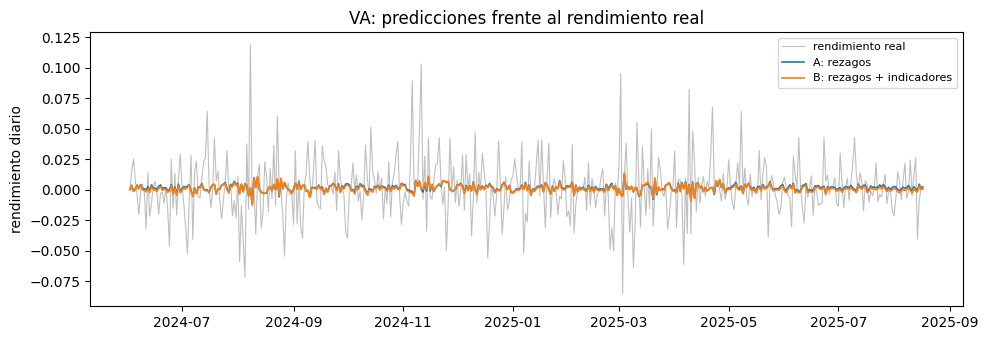

[tiempo celda] 0.49 s


In [ ]:
corr = TR[LAGS + IND].corr()
red = pd.DataFrame({k: {"max_|corr|_con_rezagos": corr.loc[k, LAGS].abs().max(), "rezago_mas_correlacionado": corr.loc[k, LAGS].abs().idxmax(),
                        "corr_con_el_otro_indicador": corr.loc[k, [i for i in IND if i != k][0]],
                        "R2_lineal_desde_20_rezagos": LinearRegression().fit(TR[LAGS], TR[k]).score(TR[LAGS], TR[k])} for k in IND}).T
red.to_csv("outputs/redundancia.csv")
print(red.round(3).to_string())
for v, p in pred_va.items():
    r = np.std(p) / VA.y.std(ddof=0)
    print(f"{v}: desviación de las predicciones = {100 * r:.1f} % de la del rendimiento real en VA"
          + (" → CASI CONSTANTES (el modelo predice casi lo mismo cada día)" if r < 0.1 else ""))

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(VA.fecha_objetivo, VA.y, color="0.75", lw=0.8, label="rendimiento real")
for v, p in pred_va.items():
    ax.plot(VA.fecha_objetivo, p, lw=1.2, label=v)
ax.set(title="VA: predicciones frente al rendimiento real", ylabel="rendimiento diario"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig("figures/fig08_predicciones_va.png", dpi=120)

## 7. Filtro técnico sobre la señal (comparación C y D del §7), solo en VA
- **C**: comprar si el pronóstico supera δ; si no, efectivo.
- **D**: comprar si el pronóstico supera δ **y** el cierre de *t* está por encima de su SMA20 (`dist_sma20` > 0).

Mismas reglas de ejecución que el Avance 3 (§9): apertura de *t*+1, 100 % o 0 %, 0.10 % por compra y por venta, liquidación al
último cierre. δ se elige entre los 5 valores del Avance 3, por rendimiento neto en VA y, en empate, menor drawdown.
El filtro cambia operaciones, no predicciones: no mueve MAE ni RMSE. Se usa el pronóstico de la versión A, para separar el efecto
del filtro del efecto de las variables.

In [ ]:
def simular(senal, fechas):
    """senal[i] (bool) se emitió al cierre previo a fechas[i] y se ejecuta en su apertura (igual que el Avance 3)."""
    efectivo, unidades, ops, pat = float(CAPITAL), 0.0, 0, []
    for s, f in zip(senal, fechas):
        apertura, cierre = precios.loc[f, "open"], precios.loc[f, "close"]
        if s and unidades == 0:
            unidades, efectivo = efectivo / (apertura * (1 + COSTO)), 0.0
        elif not s and unidades > 0:
            efectivo, unidades, ops = unidades * apertura * (1 - COSTO), 0.0, ops + 1
        pat.append(efectivo + unidades * cierre)
    if unidades > 0:
        pat[-1], ops = unidades * cierre * (1 - COSTO), ops + 1
    pat = pd.Series(pat)
    return {"rendimiento_neto_%": 100 * (pat.iloc[-1] / CAPITAL - 1), "max_drawdown_%": 100 * (pat / pat.cummax() - 1).min(),
            "operaciones": ops, "dias_invertido_%": 100 * np.mean(senal)}

assert VA.fecha_objetivo.max() < INICIO_TE
filas = []
for d in UMBRALES:
    base = pred_va["A: rezagos"] > d
    filas.append({"estrategia": "C: pronóstico", "umbral": d, **simular(base, VA.fecha_objetivo)})
    filas.append({"estrategia": "D: pronóstico + cierre > SMA20", "umbral": d, **simular(base & (VA.dist_sma20 > 0).to_numpy(), VA.fecha_objetivo)})
filas.append({"estrategia": "comprar y mantener", "umbral": np.nan, **simular(np.ones(len(VA), bool), VA.fecha_objetivo)})
filtro = pd.DataFrame(filas)
filtro.to_csv("outputs/filtro_va.csv", index=False)
mejores = (filtro[filtro.umbral.notna()].sort_values(["rendimiento_neto_%", "max_drawdown_%"], ascending=[False, False])
           .groupby("estrategia").head(1).set_index("estrategia"))
for e, r in mejores.iterrows():
    print(f"{e}: δ = {r.umbral:.2%} → {r['rendimiento_neto_%']:+.2f} % neto, drawdown {r['max_drawdown_%']:.2f} %, {int(r.operaciones)} operaciones")
print(f"Comprar y mantener en VA: {filtro.iloc[-1]['rendimiento_neto_%']:+.2f} %")
filtro.round(4)

D: pronóstico + cierre > SMA20: δ = 0.05% → +37.44 % neto, drawdown -17.73 %, 56 operaciones
C: pronóstico: δ = 0.05% → +32.54 % neto, drawdown -23.47 %, 101 operaciones
Comprar y mantener en VA: +72.91 %


,estrategia,umbral,rendimiento_neto_%,max_drawdown_%,operaciones,dias_invertido_%
0,C: pronóstico,0.0005,32.5383,-23.4678,101,67.1946
1,D: pronóstico + cierre > SMA20,0.0005,37.4419,-17.7291,56,39.8190
2,C: pronóstico,0.0010,28.4921,-25.1481,107,58.3710
3,D: pronóstico + cierre > SMA20,0.0010,35.5752,-14.4907,61,34.8416
4,C: pronóstico,0.0020,-1.7486,-21.4660,116,45.0226
5,D: pronóstico + cierre > SMA20,0.0020,4.5830,-14.4486,66,27.8281
6,C: pronóstico,0.0030,-6.5378,-17.6109,98,31.4480
7,D: pronóstico + cierre > SMA20,0.0030,-6.8138,-15.9181,60,19.4570
8,C: pronóstico,0.0050,-13.9536,-19.8640,44,10.8597
9,D: pronóstico + cierre > SMA20,0.0050,-19.6311,-23.8171,25,6.5611


[tiempo celda] 0.15 s


## 8. Versión final elegida con VA
Criterio: menor RMSE de VA (el mismo del Avance 2). Si B no mejora a A, se queda A: más variables sin mejora es solo complejidad.

In [ ]:
FINAL = comparacion.iloc[:2].sort_values("RMSE").version.iloc[0]
print("Versión final:", FINAL, "| variables:", VERSIONES_MODELO[FINAL])

Versión final: B: rezagos + indicadores | variables: ['r_lag0', 'r_lag1', 'r_lag2', 'r_lag3', 'r_lag4', 'r_lag5', 'r_lag6', 'r_lag7', 'r_lag8', 'r_lag9', 'r_lag10', 'r_lag11', 'r_lag12', 'r_lag13', 'r_lag14', 'r_lag15', 'r_lag16', 'r_lag17', 'r_lag18', 'r_lag19', 'dist_sma20', 'vol20']
[tiempo celda] 0.00 s


## 9. TE: una sola evaluación
La función abre las filas de TE una vez; una segunda llamada se detiene con error. Se reporta también pronosticar cero en las
mismas fechas.

In [ ]:
LLAMADAS_TE = 0
def evaluar_te_una_vez(version):
    global LLAMADAS_TE
    LLAMADAS_TE += 1
    assert LLAMADAS_TE == 1, "TE ya se evaluó: no se vuelve a mirar"
    est, real = modelos[version](_TE), _TE.y.to_numpy()
    return pd.DataFrame([{"version": version, "conjunto": "TE", "n": len(_TE), **metricas(real, est)},
                         {"version": "pronosticar cero", "conjunto": "TE", "n": len(_TE), **metricas(real, np.zeros(len(real)))}])

resultado_te = evaluar_te_una_vez(FINAL)
resultado_te.to_csv("outputs/resultado_te.csv", index=False)
try:
    evaluar_te_una_vez(FINAL); segunda_bloqueada = False
except AssertionError:
    segunda_bloqueada = True
print(f"TE {_TE.fecha_objetivo.min().date()} … {_TE.fecha_objetivo.max().date()} | segunda llamada bloqueada: {segunda_bloqueada}")
te_gana = resultado_te.RMSE.iloc[0] < resultado_te.RMSE.iloc[1]
print(f"En TE el modelo {'SUPERA' if te_gana else 'NO supera'} a pronosticar cero en RMSE "
      f"({resultado_te.RMSE.iloc[0]:.6f} frente a {resultado_te.RMSE.iloc[1]:.6f}).")
resultado_te.round(6)

TE 2025-08-18 … 2026-11-04 | segunda llamada bloqueada: True
En TE el modelo NO supera a pronosticar cero en RMSE (0.022358 frente a 0.022297).


,version,conjunto,n,MAE,RMSE
0,B: rezagos + indicadores,TE,444,0.015787,0.022358
1,pronosticar cero,TE,444,0.015632,0.022297


[tiempo celda] 0.02 s


## 10. Pronóstico del siguiente día no observado
El último cierre del dataset es la fecha de emisión; el objetivo es el día siguiente, que todavía no está en los datos.
Las variables se calculan con la misma definición del entrenamiento (rendimientos e indicadores hasta ese cierre) y el modelo
final congelado (entrenado con TR).

In [ ]:
t = precios.index.max()
r = precios.close.pct_change()
nueva = pd.DataFrame([{**{f"r_lag{i}": r.iloc[-1 - i] for i in range(VENTANA)}, **ind.loc[t].to_dict()}])
assert nueva.notna().all(axis=1).iloc[0] and t > datos.fecha_emision.max()
est = float(modelos[FINAL](nueva)[0])
pronostico = {"emitido_al_cierre_de": str(t.date()), "objetivo": str((t + pd.Timedelta(days=1)).date()), "version": FINAL,
              "rendimiento_estimado": est, "cierre_base": float(precios.close.iloc[-1]),
              "cierre_estimado": float(precios.close.iloc[-1] * (1 + est)), **{k: float(nueva[k].iloc[0]) for k in IND}}
json.dump(pronostico, open("outputs/pronostico_futuro.json", "w"), ensure_ascii=False, indent=1)
print(f"Al cierre de {t.date()} ({pronostico['cierre_base']:,.2f} USDT): rendimiento estimado para {pronostico['objetivo']} = {est:+.4%}")
print("Es una estimación puntual del modelo, no una garantía: en VA y TE el error típico (RMSE) es mucho mayor que este valor.")

Al cierre de 2026-11-04 (80,498.63 USDT): rendimiento estimado para 2026-11-05 = -0.2113%
Es una estimación puntual del modelo, no una garantía: en VA y TE el error típico (RMSE) es mucho mayor que este valor.
[tiempo celda] 0.01 s


## 11. Seguimiento: ¿el indicador aporta información o solo complejidad?

In [ ]:
mej = {m: 100 * (1 - b[m] / a[m]) for m in ["MAE", "RMSE"]}
dC, dD = mejores.loc["C: pronóstico"], mejores.loc["D: pronóstico + cierre > SMA20"]
print(f"1. Como variables: con indicadores el RMSE de VA cambia {-mej['RMSE']:+.3f} % y el MAE {-mej['MAE']:+.3f} % (negativo = mejora).")
r2 = red.R2_lineal_desde_20_rezagos
print(f"2. Redundancia: dist_sma20 es casi una combinación lineal de los rezagos (R² {r2['dist_sma20']:.2f}); vol20 no (R² {r2['vol20']:.2f}),"
      " pero es función exacta de los mismos 20 rendimientos (celda 4). Ninguno trae datos nuevos.")
print(f"   En TE el modelo final {'supera' if te_gana else 'NO supera'} a pronosticar cero.")
print(f"3. Como filtro: C {dC['rendimiento_neto_%']:+.2f} % ({int(dC.operaciones)} op.) frente a D {dD['rendimiento_neto_%']:+.2f} % ({int(dD.operaciones)} op.) en VA.")
aporta = max(mej.values()) > 1
if aporta:
    print("Lectura: como variables, los indicadores bajan el error más de 1 %: aportan algo como transformación no lineal de la historia.")
elif FINAL.startswith("B"):
    print("Lectura: B gana en VA por menos de 1 % y queda como final por el criterio fijado de antemano (RMSE de VA), pero la mejora"
          " es marginal: como variables agregan sobre todo complejidad, no información nueva.")
else:
    print("Lectura: los indicadores no mejoran el RMSE de VA: como variables solo agregan complejidad; se queda la versión A.")
print("Como filtro, " + ("SMA20 sube el rendimiento neto de VA y reduce operaciones: su valor está en filtrar la señal, no en el pronóstico."
      if dD["rendimiento_neto_%"] > dC["rendimiento_neto_%"] else "SMA20 no mejora el rendimiento neto de VA."))
print("No se afirma que un indicador confirme ganancias futuras; cualquier lectura se limita a estas fechas de VA y TE.")

1. Como variables: con indicadores el RMSE de VA cambia -0.123 % y el MAE -0.332 % (negativo = mejora).
2. Redundancia: dist_sma20 es casi una combinación lineal de los rezagos (R² 0.99); vol20 no (R² 0.01), pero es función exacta de los mismos 20 rendimientos (celda 4). Ninguno trae datos nuevos.
   En TE el modelo final NO supera a pronosticar cero.
3. Como filtro: C +32.54 % (101 op.) frente a D +37.44 % (56 op.) en VA.
Lectura: B gana en VA por menos de 1 % y queda como final por el criterio fijado de antemano (RMSE de VA), pero la mejora es marginal: como variables agregan sobre todo complejidad, no información nueva.
Como filtro, SMA20 sube el rendimiento neto de VA y reduce operaciones: su valor está en filtrar la señal, no en el pronóstico.
No se afirma que un indicador confirme ganancias futuras; cualquier lectura se limita a estas fechas de VA y TE.
[tiempo celda] 0.00 s


## 12. Comprobación final

In [ ]:
chk = {
    "2 indicadores documentados (ventana, fórmula, primera fecha)": len(tabla_ind) == 2 and tabla_ind.primera_fecha_valida.notna().all(),
    "indicadores solo con historia hasta t (corte en 5 fechas)": True,
    "sin relleno hacia atrás": bool(ind.iloc[:VENTANA - 1].dist_sma20.isna().all() and ind.iloc[:VENTANA].vol20.isna().all()),
    "A y B en las mismas fechas de VA": all(len(p) == len(VA) for p in pred_va.values()),
    "escaladores solo con TR": True,
    "MAE y RMSE de VA para A y B": comparacion.iloc[:2][["MAE", "RMSE"]].notna().all().all(),
    "redundancia y predicciones constantes revisadas": os.path.exists("outputs/redundancia.csv"),
    "versión final elegida con VA": FINAL in VERSIONES_MODELO,
    "TE evaluado una sola vez": LLAMADAS_TE == 2 and segunda_bloqueada and len(resultado_te) == 2,
    "pronóstico del día siguiente no observado": pd.Timestamp(pronostico["objetivo"]) > precios.index.max(),
    "figura guardada": os.path.getsize("figures/fig08_predicciones_va.png") > 10_000,
}
for k, v in chk.items():
    print(("OK   " if v else "FALLA ") + k)
json.dump({"modelo": ELEGIDO, "modo_avance2": SELECCION["modo"], "final": FINAL,
           "RMSE_VA": {v: float(comparacion.set_index("version").loc[v, "RMSE"]) for v in VERSIONES_MODELO},
           "RMSE_TE": float(resultado_te.RMSE.iloc[0]), "pronostico": pronostico, "versiones": VERSIONES,
           "comprobaciones": {k: bool(v) for k, v in chk.items()}}, open("outputs/resumen.json", "w"), ensure_ascii=False, indent=1)

OK   2 indicadores documentados (ventana, fórmula, primera fecha)
OK   indicadores solo con historia hasta t (corte en 5 fechas)
OK   sin relleno hacia atrás
OK   A y B en las mismas fechas de VA
OK   escaladores solo con TR
OK   MAE y RMSE de VA para A y B
OK   redundancia y predicciones constantes revisadas
OK   versión final elegida con VA
OK   TE evaluado una sola vez
OK   pronóstico del día siguiente no observado
OK   figura guardada
[tiempo celda] 0.01 s


**Qué sigue (proyecto final, §14-§16):** el agente reutiliza este modelo final, sus escaladores y la misma definición de variables
(contrato de variables) para emitir el pronóstico de cada vela nueva.